# P03 — 믹싱헤드 4번 유압유 누수 → 샤프트 몸통 오링·하우징 볼트 교체 (2026-10-27 10:40)

정리본: [`cases/P03.md`](cases/P03.md). 원시 데이터는 `cache/raw/pump/` 일별 CSV, CSV에 없는 릴레이·유압 비트만 DB(하루 캐시). 공용 함수 [`hd4_common.py`](hd4_common.py).

| 단계 | 내용 |
|---|---|
| 1 | 일지 |
| 2 | 그때 경고 이력 (P7·I7) |
| 3 | 작업 구간 원시 신호 — HD4 정지·재가동 |
| 4 | 헤드 인젝션 실측 시간 (ON_T·OFF_T, SOL 켜짐 시간) |
| 5 | 유압 유닛 압력 스위치 (유압 1~4) |
| 6 | 고정 조건으로 본 원료 저항 — 작업 전후 |
| 7 | 재생 — 일별 피처 추세, 그때 모델 상태 |

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from review_lib import paths, plot          # plot: 한글 글꼴 설정
import hd4_common as h
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 80)
FIGS = paths.CHECK_DIRS["pump"] / "figs"; FIGS.mkdir(exist_ok=True)
INC = pd.read_csv("labels_incidents.csv")
INC = INC[INC.incident_id.isin(["P02", "P03", "P04"])]
EV = h.EVENTS["P03 믹싱헤드 오링"]
from review_lib import db

## 1. 일지

공무반 기록 하나뿐이다. 유압유 누수는 원료 계통이 아니라 믹싱헤드를 여닫는 유압 계통이다.

In [2]:
h.actions("P03")[["작업ID", "journal", "start_dt", "end_dt", "설비상세", "조치", "부품태그", "map_note"]]

,작업ID,journal,start_dt,end_dt,설비상세,조치,부품태그,map_note
4,G-02-004,공무반,2026-10-27 10:40:00,2026-10-27 11:30:00,믹싱헤드 4번 ( 유압유누수 ),믹싱헤드 샤프트몸통 오링교체 및 하우징볼트교체,오링;호스;믹싱헤드;볼트·축·체인,믹싱헤드 4번 유압유 누수 → 샤프트몸통 오링·하우징볼트 교체. 유압 계통은 원료 압력과 별개라 펌프 지표에 안 보일 수 있음


## 2. 그때 경고 이력 (P7·I7)

In [3]:
ep = h.episodes()
ep[(ep.onset < "2026-10-28") & (ep.last_detected > "2026-10-20")][["episode_id", "key", "onset", "last_detected", "cleared", "reasons", "message_first", "top_features"]]

,episode_id,key,onset,last_detected,cleared,reasons,message_first,top_features
2,W0003,I7,2026-10-15 18:59:26.015,2026-10-25 08:50:00.624,NaT,pump_line_resistance_low;pump_head_resistance_high;pump_line_resistance_high,토출 배관 저항 감소 · 같은 유량 대비 압력 하강 (노즐 열림·누설 의심),r_phys;P0;decel_half_sec;release_half_sec;t_self
11,W0012,P7,2026-10-17 06:57:02.215,2026-10-24 22:37:51.791,2026-10-25 08:50:00.623,pump_line_resistance_high;pump_head_resistance_high,토출 배관·노즐 저항 증가 · 같은 유량 대비 압력 상승,r_phys;pt_std;P0;t_self;decel_half_sec
65,W0066,P7,2026-10-26 07:00:57.847,2026-10-28 09:17:57.259,2026-10-28 13:30:00.125,pump_head_resistance_high,헤드 토출 저항 증가 · POL·ISO 동시 압력 상승 (노즐·믹싱헤드 점검) — 헤드 HD4-1 P7·I7,r_phys;P0;pt_std;t_self;decel_half_sec
66,W0067,I7,2026-10-26 07:00:57.847,2026-11-06 13:45:55.878,NaT,pump_head_resistance_high;pump_line_resistance_high,헤드 토출 저항 증가 · POL·ISO 동시 압력 상승 (노즐·믹싱헤드 점검) — 헤드 HD4-1 P7·I7,r_phys;P0;t_self;pt_std;release_half_sec


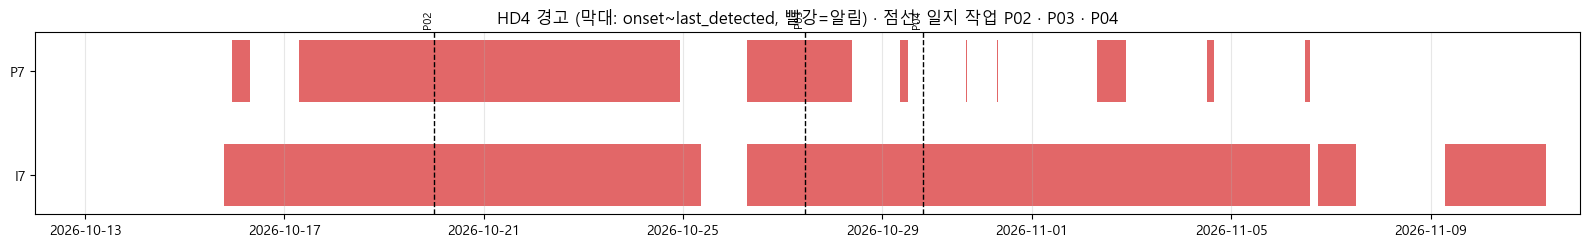

In [4]:
fig, ax = plt.subplots(figsize=(16, 2.6))
plot.timeline(h.episodes(), INC, start=pd.Timestamp("2026-10-12"), end=pd.Timestamp("2026-11-12"), ax=ax)
ax.set_title("HD4 경고 (막대: onset~last_detected, 빨강=알림) · 점선: 일지 작업 P02 · P03 · P04")
fig.tight_layout(); fig.savefig(FIGS / "HD4_timeline.png", dpi=110, bbox_inches="tight")

## 3. 작업 구간 원시 신호

In [5]:
# 원시 데이터 — cache/raw/pump 일별 CSV + HD4 릴레이(DB, 하루 캐시). 10-06 ~ 11-12 전체 약 30초
R = h.raw()
R[["FT_P7", "PT_P7", "Hz_P7", "BU_P7", "FT_I7", "PT_I7", "Hz_I7", "BU_I7", "Pump_Run_P7", "FWD_P7", "INJ_SOL_HD4"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
FT_P7,6339884.0,1426.8,1155.5,0.0,0.0,1811.0,2614.0,9978.0
PT_P7,6210010.0,76.5,57.5,0.0,3.0,97.0,128.0,187.0
Hz_P7,6339884.0,2890.4,631.1,2500.0,2500.0,2500.0,3622.0,4320.0
BU_P7,6339884.0,0.3,0.4,0.0,0.0,0.0,1.0,1.0
FT_I7,6339884.0,647.8,545.7,0.0,0.0,771.0,1119.0,9554.0
PT_I7,6327369.0,35.6,34.7,0.0,3.0,28.0,58.0,141.0
Hz_I7,6339884.0,3663.0,1105.1,3000.0,3000.0,3000.0,4081.0,6354.0
BU_I7,6339884.0,0.3,0.4,0.0,0.0,0.0,1.0,1.0
Pump_Run_P7,6339884.0,0.6,0.5,0.0,0.0,1.0,1.0,1.0
FWD_P7,6339598.0,0.6,0.5,0.0,0.0,1.0,1.0,1.0


In [6]:
w = R.loc["2026-10-27 10:20":"2026-10-27 11:50"]
cols = ["FT_P7", "PT_P7", "Hz_P7", "BU_P7", "FT_I7", "PT_I7", "Pump_Run_P7", "FWD_P7", "INJ_SOL_HD4"]
w[cols].resample("5min").agg(["min", "max"])

FT_P7       PT_P7        Hz_P7       BU_P7     FT_I7       PT_I7        Pump_Run_P7     FWD_P7      INJ_SOL_HD4     
                      min   max   min    max   min   max   min max   min   max   min    max         min max    min  max         min  max
Time                                                                                                                                    
2026-10-27 10:20:00  1811  3111  92.0  165.0  2500  4320     0   1   758  1600  27.0  115.0           1   1    1.0  1.0         0.0  1.0
2026-10-27 10:25:00  1811  3111  91.0  165.0  2500  4320     0   1   758  1591  27.0  115.0           1   1    1.0  1.0         0.0  1.0
2026-10-27 10:30:00  1810  3111  92.0  170.0  2500  4320     0   1   758  1566  28.0  115.0           1   1    1.0  1.0         0.0  1.0
2026-10-27 10:35:00  1811  3111  92.0  166.0  2500  4320     0   1   758  1591  28.0  119.0           1   1    1.0  1.0         0.0  1.0
2026-10-27 10:40:00     0  3096   0.0  165.0  2500  4320     0   1     0  1542   0.0  113.0           0   1    0.0  1.0         0.0  1.0
2026-10-27 10:45:00     0     0   0.0    9.0  2500  2500     0   0     0     0   0.0    7.0           0   0    0.0  0.0         0.0  0.0
2026-10-27 10:50:00     0     0   0.0    8.0  2500  2500     0   0     0     0   0.0    7.0           0   0    0.0  0.0         0.0  0.0
2026-10-27 10:55:00     0     0   0.0    8.0  2500  2500     0   0     0     0   0.0    7.0           0   0    0.0  0.0         0.0  0.0
2026-10-27 11:00:00     0     0   0.0    8.0  2500  2500     0   0     0     0   0.0    7.0           0   0    0.0  0.0         0.0  0.0
2026-10-27 11:05:00     0     0   0.0    8.0  2500  2500     0   0     0     0   0.0    7.0           0   0    0.0  0.0         0.0  0.0
2026-10-27 11:10:00     0     0   0.0    8.0  2500  2500     0   0     0     0   0.0    7.0           0   0    0.0  0.0         0.0  0.0
2026-10-27 11:15:00     0     0   0.0    8.0  2500  2500     0   0     0     0   0.0   15.0           0   1    0.0  1.0         0.0  0.0
2026-10-27 11:20:00   380  1833  90.0  113.0  2500  2500     0   0   410   784  27.0   35.0           1   1    1.0  1.0         0.0  0.0
2026-10-27 11:25:00  1811  1840  99.0  111.0  2500  2500     0   0   758   796  28.0   35.0           1   1    1.0  1.0         0.0  0.0
2026-10-27 11:30:00  1797  3096  97.0  174.0  2500  4320     0   1   758  1542  28.0  115.0           1   1    1.0  1.0         0.0  1.0
2026-10-27 11:35:00  1811  3096  94.0  175.0  2500  4320     0   1   758  1566  28.0  115.0           1   1    1.0  1.0         0.0  1.0
2026-10-27 11:40:00  1811  3096  95.0  171.0  2500  4320     0   1   758  1517  27.0  114.0           1   1    1.0  1.0         0.0  1.0
2026-10-27 11:45:00  1811  3096  94.0  169.0  2500  4320     0   1   758  1504  28.0  115.0           1   1    1.0  1.0         0.0  1.0
2026-10-27 11:50:00  1811  2994  95.0  158.0  2500  3971     0   1   758  1504  28.0  108.0           1   1    1.0  1.0         0.0  1.0

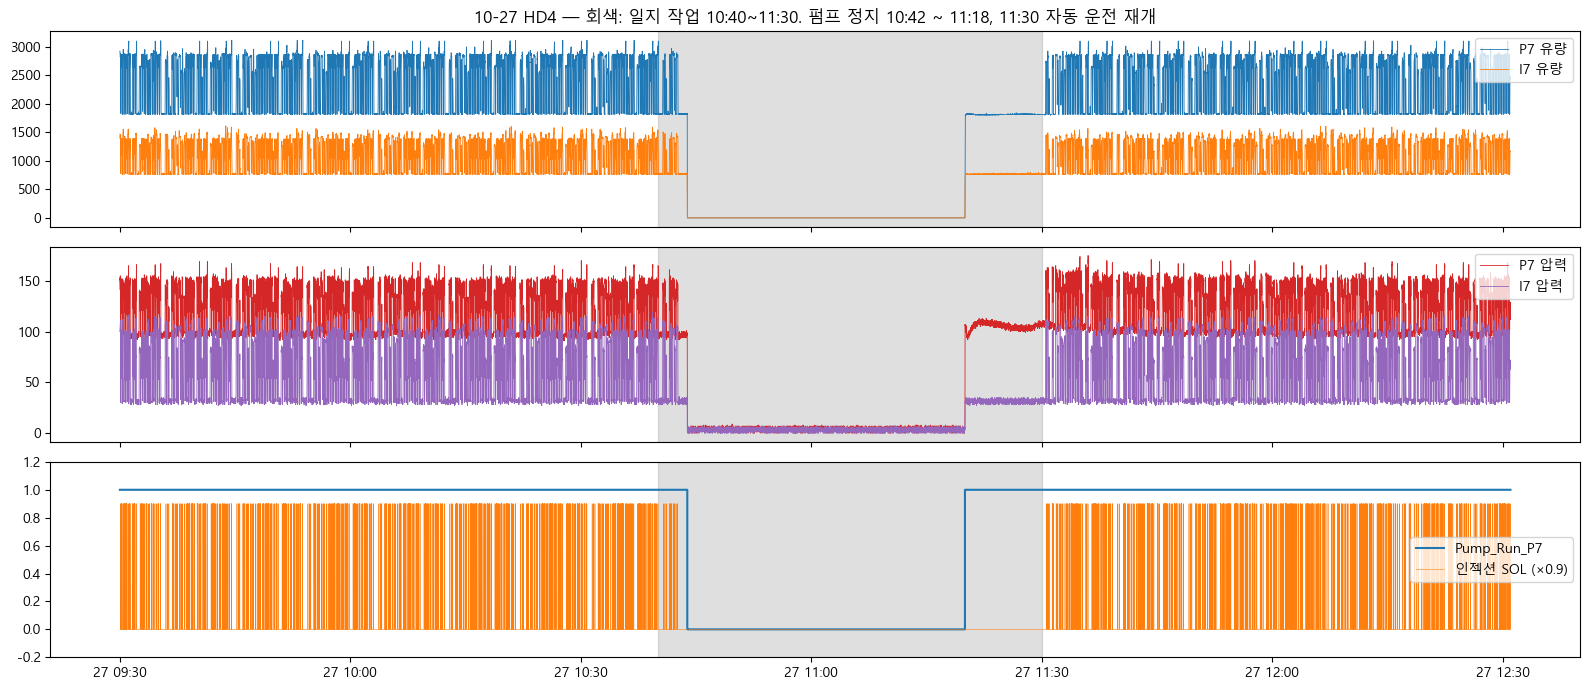

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(16, 7), sharex=True)
seg = R.loc["2026-10-27 09:30":"2026-10-27 12:30"]
axes[0].plot(seg.index, seg.FT_P7, lw=0.6, label="P7 유량"); axes[0].plot(seg.index, seg.FT_I7, lw=0.6, label="I7 유량"); axes[0].legend(loc="upper right")
axes[1].plot(seg.index, seg.PT_P7, lw=0.6, color="tab:red", label="P7 압력"); axes[1].plot(seg.index, seg.PT_I7, lw=0.6, color="tab:purple", label="I7 압력"); axes[1].legend(loc="upper right")
axes[2].step(seg.index, seg.Pump_Run_P7, where="post", label="Pump_Run_P7")
axes[2].step(seg.index, seg.INJ_SOL_HD4 * 0.9, where="post", lw=0.4, label="인젝션 SOL (×0.9)"); axes[2].legend(loc="center right"); axes[2].set_ylim(-0.2, 1.2)
for ax in axes:
    ax.axvspan(*EV, color="gray", alpha=0.25)
axes[0].set_title("10-27 HD4 — 회색: 일지 작업 10:40~11:30. 펌프 정지 10:42 ~ 11:18, 11:30 자동 운전 재개")
fig.tight_layout(); fig.savefig(FIGS / "P03_window.png", dpi=110, bbox_inches="tight")

## 4. 헤드 인젝션 실측 시간

유압유가 새서 헤드 피스톤 힘이 모자라면 열고 닫는 데 시간이 더 걸릴 수 있다. 헤드 모델(`head_injection`)이 보는 값이다.
- `HD4_P1_인젝션_ON_T` · `OFF_T` (D04714·D04715): PLC 실측 타이머. 사이클 끝날 때만 갱신된다. 문턱은 ON 17 · OFF 10.
- SOL 켜짐 시간: `P00280` 켜짐 → 꺼짐.

In [8]:
E = h.injection_cycles(R)
E.groupby("day").agg(n=("on_s", "size"), on_s=("on_s", "median"), on_p90=("on_s", lambda s: s.quantile(0.9)),
                     ON_T=("ON_T", "mean"), OFF_T=("OFF_T", "mean"), ON_T_max=("ON_T", "max"), OFF_T_max=("OFF_T", "max")).loc["2026-10-15":"2026-11-05"].round(2)

,n,on_s,on_p90,ON_T,OFF_T,ON_T_max,OFF_T_max
day,,,,,,,
2026-10-15,6634,1.01,1.56,8.15,6.75,10,8
2026-10-16,6257,1.01,1.57,8.20,6.79,10,8
2026-10-17,6579,0.53,1.56,8.19,6.74,10,8
2026-10-19,6697,0.59,1.55,8.19,6.75,9,8
2026-10-20,6381,1.01,1.56,8.18,6.73,10,8
2026-10-21,5782,1.02,1.56,8.18,6.76,10,8
2026-10-22,5643,0.54,1.56,8.20,6.77,10,8
2026-10-23,6019,0.54,1.56,8.22,6.77,10,8
2026-10-24,6481,0.53,1.56,8.22,6.73,10,8


In [9]:
x = E.loc["2026-10-27 06:00":"2026-10-27 16:00"]
x.resample("20min").agg({"on_s": ["size", "median"], "ON_T": "mean", "OFF_T": "mean"}).round(2)

on_s         ON_T OFF_T
                    size median  mean  mean
on                                         
2026-10-27 06:40:00   70   0.78  8.39  6.86
2026-10-27 07:00:00  159   0.57  8.25  6.77
2026-10-27 07:20:00  127   1.02  8.28  6.86
2026-10-27 07:40:00  164   1.01  8.23  6.76
2026-10-27 08:00:00  158   0.99  8.17  6.72
2026-10-27 08:20:00  166   1.01  8.09  6.81
2026-10-27 08:40:00   66   0.99  8.17  6.76
2026-10-27 09:00:00  151   1.02  8.19  6.83
2026-10-27 09:20:00  162   1.02  8.22  6.71
2026-10-27 09:40:00  165   1.02  8.18  6.71
2026-10-27 10:00:00  170   1.02  8.06  6.77
2026-10-27 10:20:00  178   0.78  8.12  6.74
2026-10-27 10:40:00   14   1.53  8.07  6.64
2026-10-27 11:00:00    0    NaN   NaN   NaN
2026-10-27 11:20:00   75   1.01  8.23  6.89
2026-10-27 11:40:00  161   1.02  8.21  6.76
2026-10-27 12:00:00  161   1.02  8.18  6.70
2026-10-27 12:20:00  168   1.01  8.21  6.79
2026-10-27 12:40:00  160   1.02  8.16  6.78
2026-10-27 13:00:00  172   1.02  8.13  6.74
2026-10-27 13:20:00   44   1.02  8.11  6.59
2026-10-27 13:40:00  165   1.02  8.31  6.72
2026-10-27 14:00:00  164   1.01  8.11  6.77
2026-10-27 14:20:00  159   1.03  8.09  6.76
2026-10-27 14:40:00  165   1.02  8.16  6.77
2026-10-27 15:00:00  179   1.02  8.16  6.72
2026-10-27 15:20:00   90   1.02  8.21  6.78
2026-10-27 15:40:00  157   0.53  8.17  6.75
2026-10-27 16:00:00    3   1.04  7.67  7.00

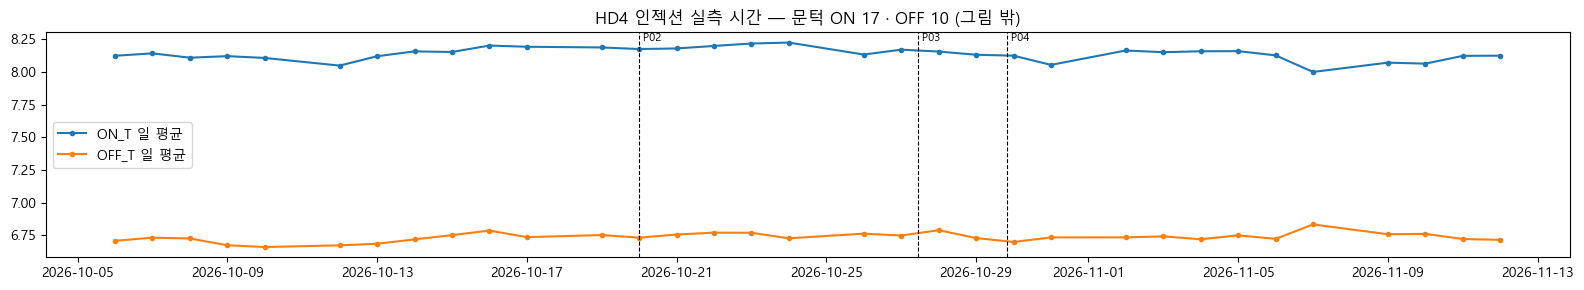

In [10]:
d = E.groupby("day")[["ON_T", "OFF_T"]].mean()
fig, ax = plt.subplots(figsize=(16, 3))
ax.plot(d.index, d.ON_T, "o-", ms=3, label="ON_T 일 평균"); ax.plot(d.index, d.OFF_T, "o-", ms=3, label="OFF_T 일 평균")
h.mark(ax, label=True); ax.legend(loc="center left"); ax.set_title("HD4 인젝션 실측 시간 — 문턱 ON 17 · OFF 10 (그림 밖)")
fig.tight_layout(); fig.savefig(FIGS / "P03_injection.png", dpi=110, bbox_inches="tight")

## 5. 유압 유닛 압력 스위치

모델 입력이 아니고 CSV에도 없다. 여기서만 DB에서 하루씩 받는다(`cache/raw/hyd_aux/`).
- `P0006C`/`P0006D` 유압4 Pressure Low/High, `P00041` 유압 4 Trip, `P00307` 유압4 INV P1 (1·2·3번도 같이)
- **유압 유닛 번호와 헤드 번호가 맞는지는 확인되지 않았다.**
- High 비트는 하루 수천 번 켜졌다 꺼진다(가압·무부하 반복). 누유가 있으면 압력이 빨리 빠져 High에 머무는 비율이 줄 것으로 보고 비교한다.

In [11]:
HYD = ["P0003E", "P0003F", "P00040", "P00041", "P00066", "P00067", "P00068", "P00069", "P0006A", "P0006B", "P0006C", "P0006D", "P00306", "P00307"]
Y = pd.concat([db.fetch_day(d, HYD, group="hyd_aux") for d in pd.date_range("2026-10-06", "2026-11-12")]).sort_index()
Y = Y[~Y.index.duplicated()][HYD]
Y = Y[Y.P00307 == 1]                                   # 유압4 인버터 가동 중만
dt = Y.index.to_series().diff().shift(-1).dt.total_seconds().clip(upper=5)
day = (Y.index - pd.Timedelta(hours=6)).date
hi = {1: "P00067", 2: "P00069", 3: "P0006B", 4: "P0006D"}
frac = pd.DataFrame({f"유압{u} High 비율": (Y[c] * dt).groupby(day).sum() / dt.groupby(day).sum() for u, c in hi.items()})
frac["유압4 Trip 횟수"] = ((Y.P00041 == 1) & (Y.P00041.shift() == 0)).groupby(day).sum()
frac = frac[dt.groupby(day).sum() > 3600 * 4]          # 가동 4시간 넘는 날
frac.index = pd.to_datetime(frac.index); frac.round(3)

,유압1 High 비율,유압2 High 비율,유압3 High 비율,유압4 High 비율,유압4 Trip 횟수
2026-10-06,0.289,0.320,0.105,0.394,0
2026-10-07,0.284,0.321,0.108,0.400,0
2026-10-08,0.301,0.372,0.096,0.367,0
2026-10-09,0.310,0.322,0.108,0.391,0
2026-10-10,0.290,0.313,0.107,0.389,0
2026-10-12,0.315,0.335,0.106,0.391,0
2026-10-13,0.308,0.360,0.109,0.413,0
2026-10-14,0.309,0.368,0.107,0.420,0
2026-10-15,0.319,0.398,0.114,0.379,0
2026-10-16,0.322,0.392,0.116,0.353,0


In [12]:
def hi_frac(a, b, c="P0006D"):
    m = (Y.index >= a) & (Y.index < b)
    return round((Y[c][m] * dt[m]).sum() / dt[m].sum(), 3)
pd.DataFrame({"구간": ["10-26 06:30~10:40", "10-27 06:30~10:40 (작업 전)", "10-27 11:30~16:00 (작업 후)", "10-27 16:00~24:00", "10-28 06:30~10:40"],
              "유압4 High 비율": [hi_frac("2026-10-26 06:30", "2026-10-26 10:40"), hi_frac("2026-10-27 06:30", "2026-10-27 10:40"),
                                  hi_frac("2026-10-27 11:30", "2026-10-27 16:00"), hi_frac("2026-10-27 16:00", "2026-10-28 00:00"),
                                  hi_frac("2026-10-28 06:30", "2026-10-28 10:40")]})

,구간,유압4 High 비율
0,10-26 06:30~10:40,0.326
1,10-27 06:30~10:40 (작업 전),0.439
2,10-27 11:30~16:00 (작업 후),0.431
3,10-27 16:00~24:00,0.397
4,10-28 06:30~10:40,0.392


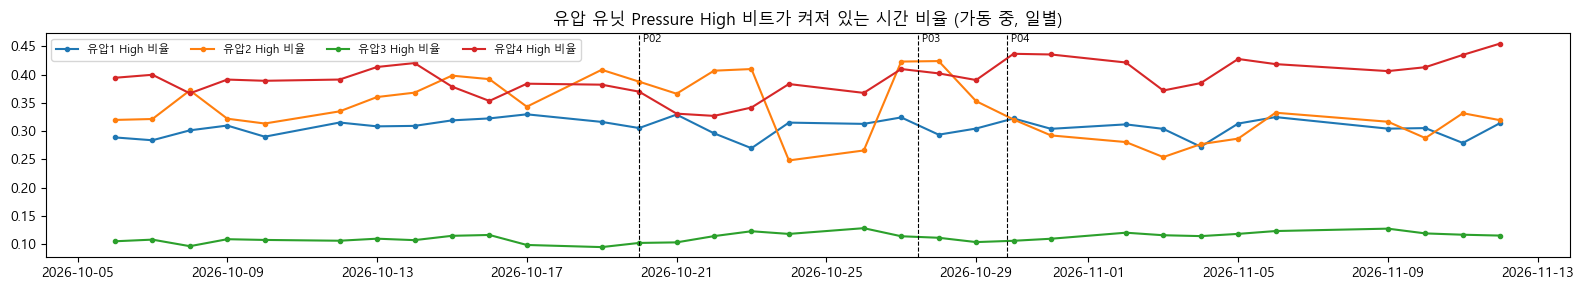

In [13]:
fig, ax = plt.subplots(figsize=(16, 3))
for c in frac.columns[:4]:
    ax.plot(frac.index, frac[c], "o-", ms=3, label=c)
h.mark(ax, label=True); ax.legend(loc="upper left", ncol=4, fontsize=8); ax.set_title("유압 유닛 Pressure High 비트가 켜져 있는 시간 비율 (가동 중, 일별)")
fig.tight_layout(); fig.savefig(FIGS / "P03_hydraulic.png", dpi=110, bbox_inches="tight")

## 6. 고정 조건으로 본 원료 저항 — 작업 전후

오링·하우징 볼트는 유압 쪽이지만 같은 믹싱헤드다. 원료 쪽 저항이 움직였는지 확인한다.

In [14]:
pd.concat({"P7 증압": h.before_after(R, "P7", *EV), "P7 순환": h.before_after(R, "P7", *EV, buildup=0),
           "I7 증압": h.before_after(R, "I7", *EV), "I7 순환": h.before_after(R, "I7", *EV, buildup=0)}).round(2)

n            FT             PT             K             
구간             전     후       전       후      전      후      전      후   변화%
      Hz                                                                
P7 증압 3929    99   104  2834.0  2834.0  141.0  141.5  17.62  17.62  0.00
      3971    93   105  2863.0  2863.0  143.0  143.0  17.54  17.52 -0.15
P7 순환 2500  5755  4384  1811.0  1811.0  101.0   99.0  30.49  30.19 -1.00
I7 증압 5631    93   105  1405.0  1405.0  101.0  101.0  51.61  51.61  0.00
      5711    99   104  1417.0  1417.0  104.0  104.0  51.46  51.32 -0.26
I7 순환 3000  5753  4384   759.0   758.0   31.0   31.0  53.83  53.83  0.00

In [15]:
# 같은 Hz 단계끼리 이어 본 증압(자동 운전) 저항 K = PT/(FT/1000)² — 레시피가 바뀌어도 비교가 된다
kp, ki = h.hz_table(R, "P7"), h.hz_table(R, "I7")
pd.concat({"P7": kp, "I7": ki}, axis=1).loc["2026-10-20":"2026-11-02"].round(2)

P7                          I7                     
Hz           3650   3901   3929   3971   5057   5631   5711   6032
day                                                               
2026-10-20  19.97  18.70  17.62    NaN  43.30    NaN  42.80  43.02
2026-10-21  19.88    NaN  17.43    NaN  43.33    NaN  42.80    NaN
2026-10-22  20.03    NaN  17.56  17.51  43.33  42.83  42.80    NaN
2026-10-23  19.93  18.37  17.57  18.21  52.24  51.67  51.80  51.66
2026-10-24  19.97    NaN  17.56  17.57  52.24  51.61  51.35    NaN
2026-10-26  20.11    NaN  17.54  17.43  52.24  51.61  51.35    NaN
2026-10-27  19.96    NaN  17.62  17.54  52.11  51.61  51.35    NaN
2026-10-28  18.58    NaN  16.19  16.48  51.80  51.61  51.30    NaN
2026-10-29  18.60    NaN  16.19    NaN  51.62    NaN  51.30    NaN
2026-10-30  18.38  16.95  16.16    NaN  51.98    NaN  51.30  51.66
2026-10-31  18.80    NaN  16.13    NaN  52.61    NaN  51.30    NaN
2026-11-02  18.95    NaN  16.56  16.50  51.62  51.61  51.30    NaN

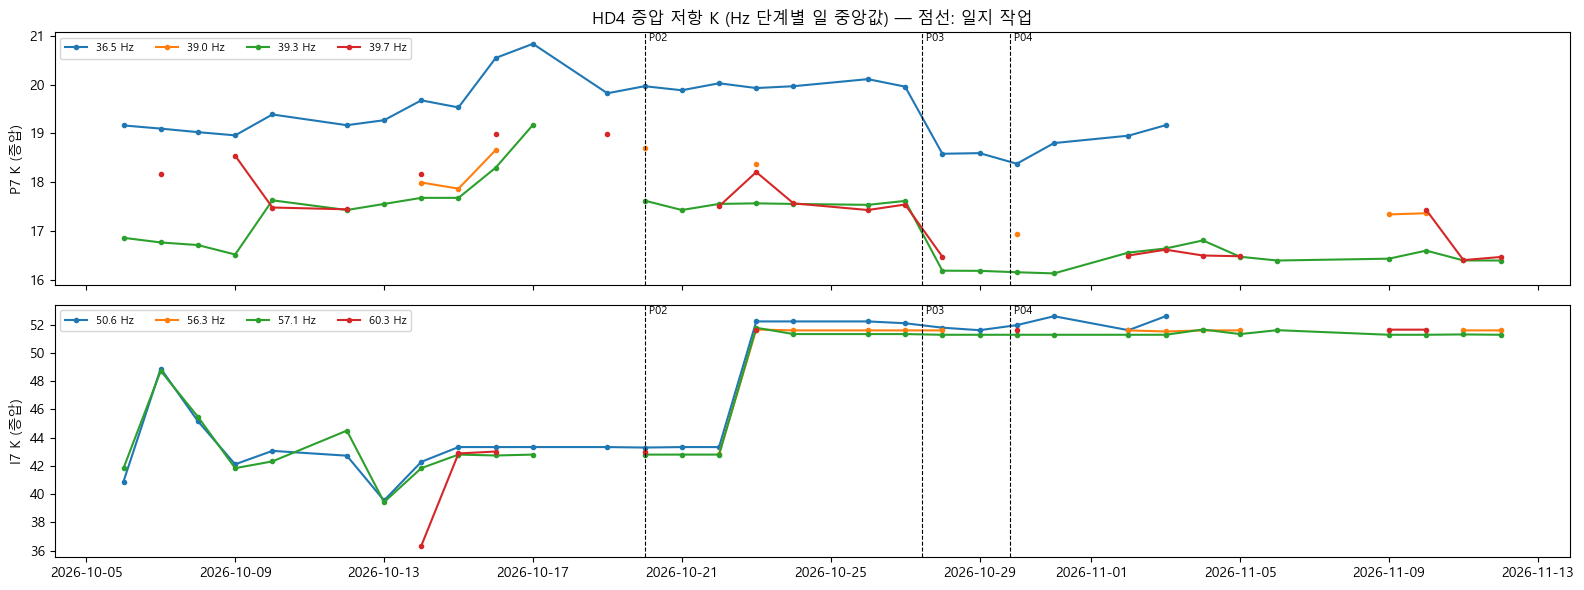

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
for ax, (p, t) in zip(axes, [("P7", kp), ("I7", ki)]):
    for hz in t.columns:
        ax.plot(t.index, t[hz], "o-", ms=3, label=f"{hz / 100:.1f} Hz")
    ax.set_ylabel(f"{p} K (증압)"); ax.legend(loc="upper left", ncol=4, fontsize=8)
    h.mark(ax, label=True)
axes[0].set_title("HD4 증압 저항 K (Hz 단계별 일 중앙값) — 점선: 일지 작업")
fig.tight_layout(); fig.savefig(FIGS / "P03_K.png", dpi=110, bbox_inches="tight")

## 7. 재생 — 일별 피처 추세, 그때 모델 상태

10:40~11:30 정지는 30분이 넘어서(`RESET_GAP_MIN`) 재가동 첫 사이클부터 창이 비워진다.

In [17]:
# 운영 펌프 모델 재생 (P7·I7, 10-06 ~ 11-12). 처음 한 번 약 1시간 반 → cache/replay/hd4_P7I7_1006_1112.pkl
C = h.replay_cycles()
dP7, dI7 = h.daily_features(C, "P7"), h.daily_features(C, "I7")
pd.concat({"P7": dP7, "I7": dI7}, axis=1).loc["2026-10-20":"2026-11-02"].round(3)

P7                                                                     ...     I7                                                                  
               n  알림창비율     PT    P0  FT_SV pump_resid r_phys    z_r   z_P0 z_resid  ...  알림창비율    PT    P0  FT_SV pump_resid r_phys    z_r   z_P0 z_resid  score
day                                                                                  ...                                                                         
2026-10-20  3085  0.364  150.0  98.0  1.001     -0.535  1.071  0.666  0.333  -0.170  ...  0.976  84.5  26.0  1.009      0.051  0.946 -1.142 -0.450  -0.044  3.551
2026-10-21  3020  0.468  148.0  98.0  1.005     -0.019  1.064  0.621  0.333  -0.002  ...  0.974  84.5  26.0  1.013      0.546  0.951 -1.041 -0.450   0.028  3.029
2026-10-22  2790  0.527  149.0  98.0  1.001     -0.534  1.067  0.579  0.333  -0.169  ...  0.970  84.0  26.0  1.009      0.066  0.946 -1.168 -0.450  -0.043  4.091
2026-10-23  3010  0.332  149.0  97.0  1.002     -0.487  1.067  0.538  0.222  -0.132  ...  0.977  99.5  31.0  0.998      0.561  1.110  2.311  0.674   0.035  0.992
2026-10-24  3075  0.261  150.5  98.0  1.003     -0.280  1.067  0.597  0.333  -0.081  ...  0.979  99.0  31.0  1.000      0.658  1.112  2.328  0.674   0.046  0.879
2026-10-26  3251  0.448  149.0  98.0  1.001     -0.534  1.067  0.544  0.333  -0.161  ...  0.978  99.0  31.0  0.998      0.550  1.109  2.280  0.674   0.037  0.972
2026-10-27  3226  0.233  149.0  98.0  1.002     -0.534  1.064  0.624  0.333  -0.169  ...  0.978  99.0  31.0  0.998      0.545  1.107  2.228  0.674   0.027  0.896
2026-10-28  3270  0.069  139.0  93.0  1.005     -0.014  0.989 -0.272 -0.222   0.001  ...  0.980  99.0  31.0  0.998      0.545  1.105  2.187  0.674   0.027  0.800
2026-10-29  3163  0.026  139.0  93.0  1.005     -0.014  0.990 -0.240 -0.222   0.001  ...  0.976  99.0  31.0  0.998      0.484  1.104  2.159  0.674   0.018  0.810
2026-10-30  3312  0.066  138.0  92.0  1.005     -0.014  0.983 -0.304 -0.300   0.001  ...  0.977  99.0  31.0  0.997      0.489  1.103  2.139  0.674   0.018  0.754
2026-10-31  3256  0.006  139.0  92.0  1.005     -0.012  0.983 -0.289 -0.300   0.002  ...  0.980  99.0  31.0  0.998      0.484  1.103  2.125  0.674   0.016  0.664
2026-11-02  3477  0.071  141.0  94.0  1.005     -0.016  1.004 -0.099 -0.100   0.000  ...  0.982  99.0  31.0  0.998      0.515  1.105  2.169  0.674   0.022  0.800

[12 rows x 22 columns]

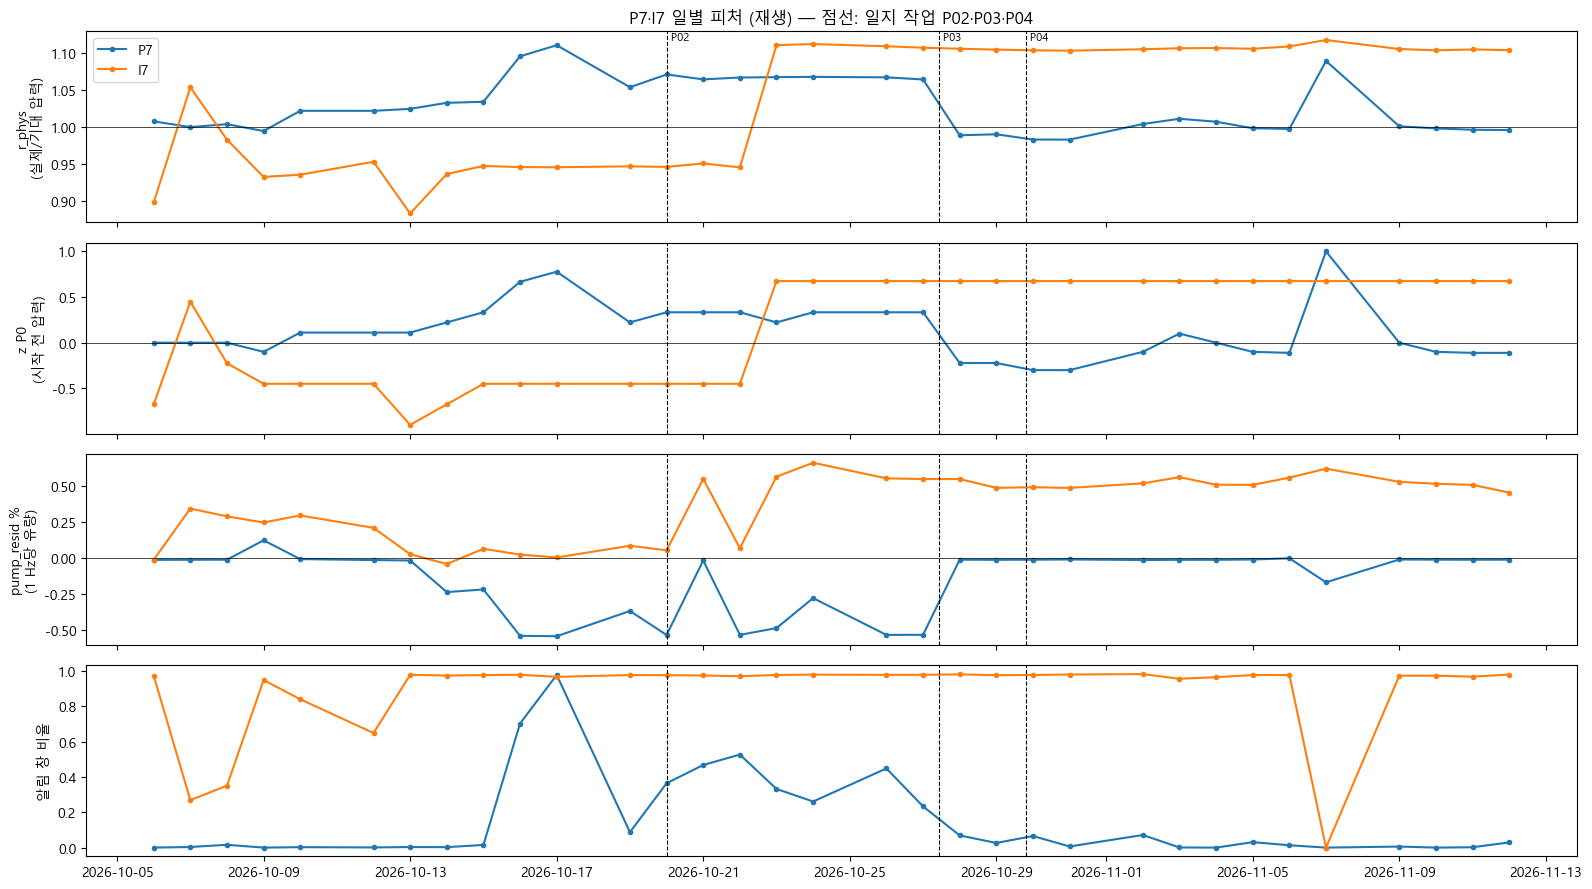

In [18]:
fig, axes = plt.subplots(4, 1, figsize=(16, 9), sharex=True)
for p, d, c in [("P7", dP7, "tab:blue"), ("I7", dI7, "tab:orange")]:
    axes[0].plot(d.index, d.r_phys, "o-", ms=3, color=c, label=p)
    axes[1].plot(d.index, d.z_P0, "o-", ms=3, color=c, label=p)
    axes[2].plot(d.index, d.pump_resid, "o-", ms=3, color=c, label=p)
    axes[3].plot(d.index, d["알림창비율"], "o-", ms=3, color=c, label=p)
axes[0].axhline(1, color="k", lw=0.5); axes[0].set_ylabel("r_phys\n(실제/기대 압력)")
axes[1].axhline(0, color="k", lw=0.5); axes[1].set_ylabel("z P0\n(시작 전 압력)")
axes[2].axhline(0, color="k", lw=0.5); axes[2].set_ylabel("pump_resid %\n(1 Hz당 유량)")
axes[3].set_ylabel("알림 창 비율"); axes[0].legend(loc="upper left")
for ax in axes:
    h.mark(ax, label=ax is axes[0])
axes[0].set_title("P7·I7 일별 피처 (재생) — 점선: 일지 작업 P02·P03·P04")
fig.tight_layout(); fig.savefig(FIGS / "P03_trend.png", dpi=110, bbox_inches="tight")

In [19]:
x = C[C.pump.isin(["P7", "I7"]) & C.t.between("2026-10-27 09:00", "2026-10-27 14:00") & (C["mode"] == "자동 운전")]
x.groupby(["pump", x.t.dt.floor("30min")]).agg(n=("t", "size"), score=("score", "median"), z_r=("zn_r_phys", "median"),
    level=("pump_level", lambda s: s.value_counts().index[0])).unstack("pump")

n          score                 z_r           level    
pump                  I7   P7        I7        P7        I7        P7    I7  P7
t                                                                              
2026-10-27 09:00:00  113  113  0.951807  0.391448  2.265752  0.719273    알림  주의
2026-10-27 09:30:00  122  122  0.891859  0.276929  2.246657  0.547245    알림  정상
2026-10-27 10:00:00  123  123  0.925640  0.288757  2.208748  0.549429    알림  주의
2026-10-27 10:30:00   48   48  0.844209  0.200011  2.159177  0.467496    알림  정상
2026-10-27 11:30:00  115  115  1.058261  0.503608  2.274810  0.804332    알림  알림
2026-10-27 12:00:00  123  123  1.012390  0.320589  2.288931  0.599776    알림  정상
2026-10-27 12:30:00  119  119  0.866470  0.276983  2.232802  0.591491    알림  정상
2026-10-27 13:00:00  105  105  1.049559  0.279096  2.251198  0.497732    알림  정상
2026-10-27 13:30:00   82   82  1.036109  0.405297  2.279225  0.700590    알림  알림